# 03 — Train and evaluate models

**Goal:** predict `position` (the *label*) from body measurements (the *features*).

Plan:
1. Hold back 20% of players as a **test set**, which the models never see during training.
2. Compare several models on the other 80% using **5-fold cross-validation**.
3. Tune the best one, evaluate it once on the test set, save it, and use it.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "..")
sns.set_theme(style="whitegrid")
ORDER = ["PG", "SG", "SF", "PF", "C"]

players = pd.read_csv("../data/processed/players.csv")

## 1. Features, label and train/test split

Two feature sets to compare:
* **core**: measurements available for (almost) every player
* **all**: core + body fat and hand size, which are missing for older players and get filled with the median

`stratify=y` keeps the same share of each position in the train and test sets.

In [2]:
CORE = ["height_cm", "weight_kg", "wingspan_cm", "reach_cm", "ape_index_cm", "reach_minus_height_cm", "bmi"]
ALL = CORE + ["body_fat_pct", "hand_length_cm", "hand_width_cm"]

X = players[ALL]
y = players["position"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
len(X_train), len(X_test)

(1344, 336)

## 2. Metrics

* **accuracy**: share of players whose exact position is predicted correctly
* **macro F1**: averages the score of each position equally, so the small C class counts as much as the others
* **adjacent accuracy**: prediction is at most one position away (a SF called PF counts as correct).
  This is a fair metric here because positions lie on a size scale.

In [3]:
RANK = {p: i for i, p in enumerate(ORDER)}

def adjacent_accuracy(y_true, y_pred):
    true = np.array([RANK[p] for p in y_true])
    pred = np.array([RANK[p] for p in y_pred])
    return np.mean(np.abs(true - pred) <= 1)

SCORING = {"accuracy": "accuracy", "macro_f1": "f1_macro", "adjacent": make_scorer(adjacent_accuracy)}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Compare models with cross-validation

Each model sits in a **Pipeline**: fill missing values → scale features → model.
Inside cross-validation the pipeline is refitted on each training fold, so no information leaks from the validation fold.

The **baseline** always guesses the most common position. Every real model must beat it.

In [4]:
def make_pipeline(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", model),
    ])

MODELS = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "k-nearest neighbours": KNeighborsClassifier(n_neighbors=25),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, random_state=42),
}
FEATURE_SETS = {"core": CORE, "all": ALL}

rows = []
for set_name, cols in FEATURE_SETS.items():
    for name, model in MODELS.items():
        scores = cross_validate(make_pipeline(model), X_train[cols], y_train, cv=CV, scoring=SCORING)
        rows.append({"model": name, "features": set_name,
                     **{m: scores[f"test_{m}"].mean() for m in SCORING}})

results = pd.DataFrame(rows).sort_values("accuracy", ascending=False).reset_index(drop=True)
results.style.format({m: "{:.1%}" for m in SCORING}).background_gradient(subset=["accuracy"], cmap="Greens")

,model,features,accuracy,macro_f1,adjacent
0,Logistic regression,all,70.7%,69.9%,99.6%
1,Logistic regression,core,70.7%,70.0%,99.6%
2,Random forest,all,69.8%,69.3%,99.0%
3,Random forest,core,69.7%,69.2%,99.2%
4,k-nearest neighbours,core,67.2%,65.5%,99.3%
5,Gradient boosting,core,66.4%,66.0%,98.7%
6,Gradient boosting,all,66.1%,65.6%,98.5%
7,k-nearest neighbours,all,66.0%,63.2%,98.4%
8,Baseline (most frequent),core,25.3%,8.1%,56.8%
9,Baseline (most frequent),all,25.3%,8.1%,56.8%


## 4. Tune the best model

`GridSearchCV` tries every combination of a few settings (*hyperparameters*) with cross-validation and keeps the best.

In [5]:
GRIDS = {
    "Logistic regression": {"model__C": [0.01, 0.1, 1, 10]},
    "k-nearest neighbours": {"model__n_neighbors": [10, 25, 50, 75], "model__weights": ["uniform", "distance"]},
    "Random forest": {"model__min_samples_leaf": [1, 5, 10, 20], "model__max_features": ["sqrt", None]},
    "Gradient boosting": {"model__learning_rate": [0.03, 0.1], "model__max_depth": [None, 3],
                          "model__l2_regularization": [0.0, 1.0]},
}

best = results[results["model"] != "Baseline (most frequent)"].iloc[0]
FEATURES = FEATURE_SETS[best["features"]]

search = GridSearchCV(make_pipeline(MODELS[best["model"]]), GRIDS[best["model"]], cv=CV, scoring="accuracy")
search.fit(X_train[FEATURES], y_train)
final_model = search.best_estimator_

best["model"], best["features"], search.best_params_, f"{search.best_score_:.1%}"

('Logistic regression', 'all', {'model__C': 1}, '70.7%')

## 5. Final check on the test set

This is the first time the model sees these players. If test accuracy is close to the cross-validation score,
the model **generalises**. A much lower score would mean it **overfitted**, i.e. it memorised the training players.

In [6]:
y_pred = final_model.predict(X_test[FEATURES])
print(classification_report(y_test, y_pred, labels=ORDER))
f"adjacent accuracy: {adjacent_accuracy(y_test, y_pred):.1%}"

              precision    recall  f1-score   support

          PG       0.82      0.80      0.81        69
          SG       0.70      0.76      0.73        76
          SF       0.58      0.62      0.60        66
          PF       0.65      0.62      0.64        85
           C       0.71      0.60      0.65        40

    accuracy                           0.69       336
   macro avg       0.69      0.68      0.68       336
weighted avg       0.69      0.69      0.69       336



'adjacent accuracy: 99.4%'

### Confusion matrix

Rows are the true position, columns the predicted one. Most mistakes should sit right next to the diagonal
(neighbouring positions), not in the corners (e.g. PG predicted as C).

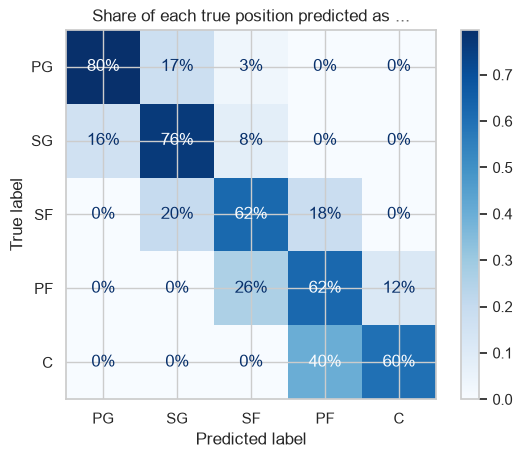

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=ORDER, cmap="Blues", normalize="true",
                                        values_format=".0%")
plt.title("Share of each true position predicted as ...");

### Which measurements matter most?

**Permutation importance:** shuffle one feature and measure how much test accuracy drops.
The bigger the drop, the more the model relies on that feature.

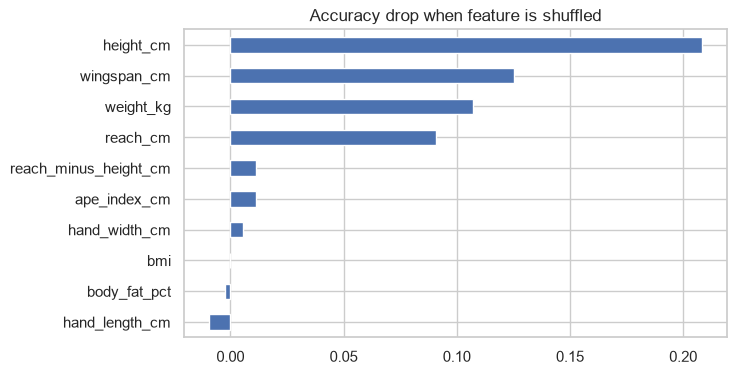

In [8]:
imp = permutation_importance(final_model, X_test[FEATURES], y_test, n_repeats=20, random_state=42)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 4), title="Accuracy drop when feature is shuffled");

## 6. Retrain on all data and save

Now that we've measured how good it is, retrain the tuned model on **all** players (train + test)
so the saved model has learned from as much data as possible.

In [9]:
import joblib
from pathlib import Path

final_model.fit(players[FEATURES], players["position"])
MODEL_PATH = Path("../models/position_model.joblib")
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump({"model": final_model, "features": FEATURES}, MODEL_PATH);

## 7. Use it

`predict_position` (in `predict.py`) returns the probability of each position.
Measurements you don't know can be left out. The model fills them in with typical values, but it's less accurate that way.

In [10]:
from predict import load_model, predict_position

bundle = load_model()
examples = {
    "small guard (185 cm, 85 kg)": dict(height_cm=185, weight_kg=85, wingspan_cm=193, reach_cm=244),
    "wing (201 cm, 98 kg)": dict(height_cm=201, weight_kg=98, wingspan_cm=210, reach_cm=265),
    "big man (213 cm, 115 kg)": dict(height_cm=213, weight_kg=115, wingspan_cm=225, reach_cm=282),
}
pd.DataFrame({name: predict_position(**m, bundle=bundle) for name, m in examples.items()}).reindex(ORDER).style.format("{:.0%}")

,"small guard (185 cm, 85 kg)","wing (201 cm, 98 kg)","big man (213 cm, 115 kg)"
PG,86%,0%,0%
SG,14%,5%,0%
SF,0%,65%,0%
PF,0%,29%,7%
C,0%,0%,93%
